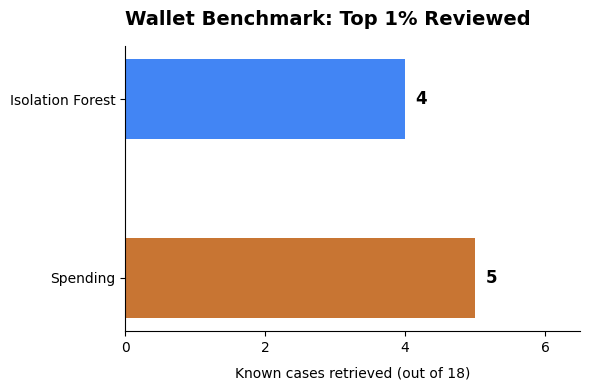

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import IsolationForest

# 1. Load dataset
df = pd.read_csv("wallet_scores.csv")

# 2. Confirmed insiders list (18 total)
confirmed_insiders = set([
    "w_2a43266bd8", "w_bc876cca82", "w_bae5b984cf", "w_b484b941ed",
    "w_651e7829e2", "w_64ac068f22", "w_d1a074f023", "w_ce629884a4",
    "w_45933e3f6b", "w_399ef66fe6", "w_b61c7eb379", "w_2023847f0c",
    "w_2c4d5f68c4", "w_efad88a8e8", "w_cd38860893", "w_ea3af901bf",
    "w_bf68f8e7eb", "w_89b41a54ca"
])

# 3. Drop specified non-feature columns
drop_cols = ["is_bot", "raw", "score", "rank", "confirmed"]
features = df.drop(columns=[c for c in drop_cols if c in df.columns])
X = features.select_dtypes(include=[np.number])

# 4. Train Isolation Forest (Top 1% contamination threshold)
iso_forest = IsolationForest(contamination=0.01, random_state=42)
df["is_insider_flagged"] = iso_forest.fit_predict(X) == -1

# 5. Compute metrics
total_wallets = len(df)
flagged_wallets = df[df["is_insider_flagged"]]
total_flagged = len(flagged_wallets)

if "wallet" in df.columns:
    retrieved_count = len(confirmed_insiders.intersection(set(flagged_wallets["wallet"])))
else:
    retrieved_count = df[df["is_insider_flagged"] & df["wallet"].isin(confirmed_insiders)].shape[0]

# 6. Create styled comparison plot
fig, ax = plt.subplots(figsize=(6, 4))

models = ["Isolation Forest", "Spending"]
counts = [retrieved_count, 5]
colors = ["#4285F4", "#C87533"]  # Matching blue and brown hex codes

bars = ax.barh(models, counts, color=colors, height=0.45)

# Axis styling matching reference screenshot
ax.set_title("Wallet Benchmark: Top 1% Reviewed", fontsize=14, fontweight="bold", loc="left", pad=15)
ax.set_xlabel("Known cases retrieved (out of 18)", fontsize=10, labelpad=8)
ax.set_xlim(0, 6.5)
ax.set_xticks([0, 2, 4, 6])

# Annotate count integer values next to bars
for bar, count in zip(bars, counts):
    ax.text(
        count + 0.15,
        bar.get_y() + bar.get_height() / 2,
        str(count),
        va="center",
        fontweight="bold",
        fontsize=12
    )

# Clean up spines (minimal left and bottom axes only)
sns.despine(top=True, right=True)
ax.grid(False)
ax.invert_yaxis()  # Isolation Forest on top

plt.tight_layout()
plt.show()

Total Flagged Anomaly Wallets: 557
Confirmed Insiders in Flagged Set: 4

--- Mean Feature Values Comparison ---
                        Normal Wallets  Flagged Anomaly Wallets  \
trade_count                  32.184192               878.631957   
unique_markets                7.463864                76.992819   
total_notional             2850.571867            370216.375407   
avg_buy_price                 0.667623                 0.814456   
concentration                 0.566046                 0.255651   
max_single_buy              584.026534             30094.318767   
market_notional_ratio         0.002420                 0.134555   
wallet_age_days              45.475607               201.845212   
position_anomaly_ratio        2.000247                 5.737516   

                        Ratio (Flagged / Normal)  
trade_count                            27.300109  
unique_markets                         10.315410  
total_notional                        129.874423  
avg_buy_price

/tmp/ipykernel_3022/1285426434.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_3022/1285426434.py:38: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[idx].set_xticklabels(["False", "True"])
/tmp/ipykernel_3022/1285426434.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_3022/1285426434.py:38: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[idx].set_xticklabels(["False", "True"])
/tmp/ipykernel_3022/1285426434.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is de

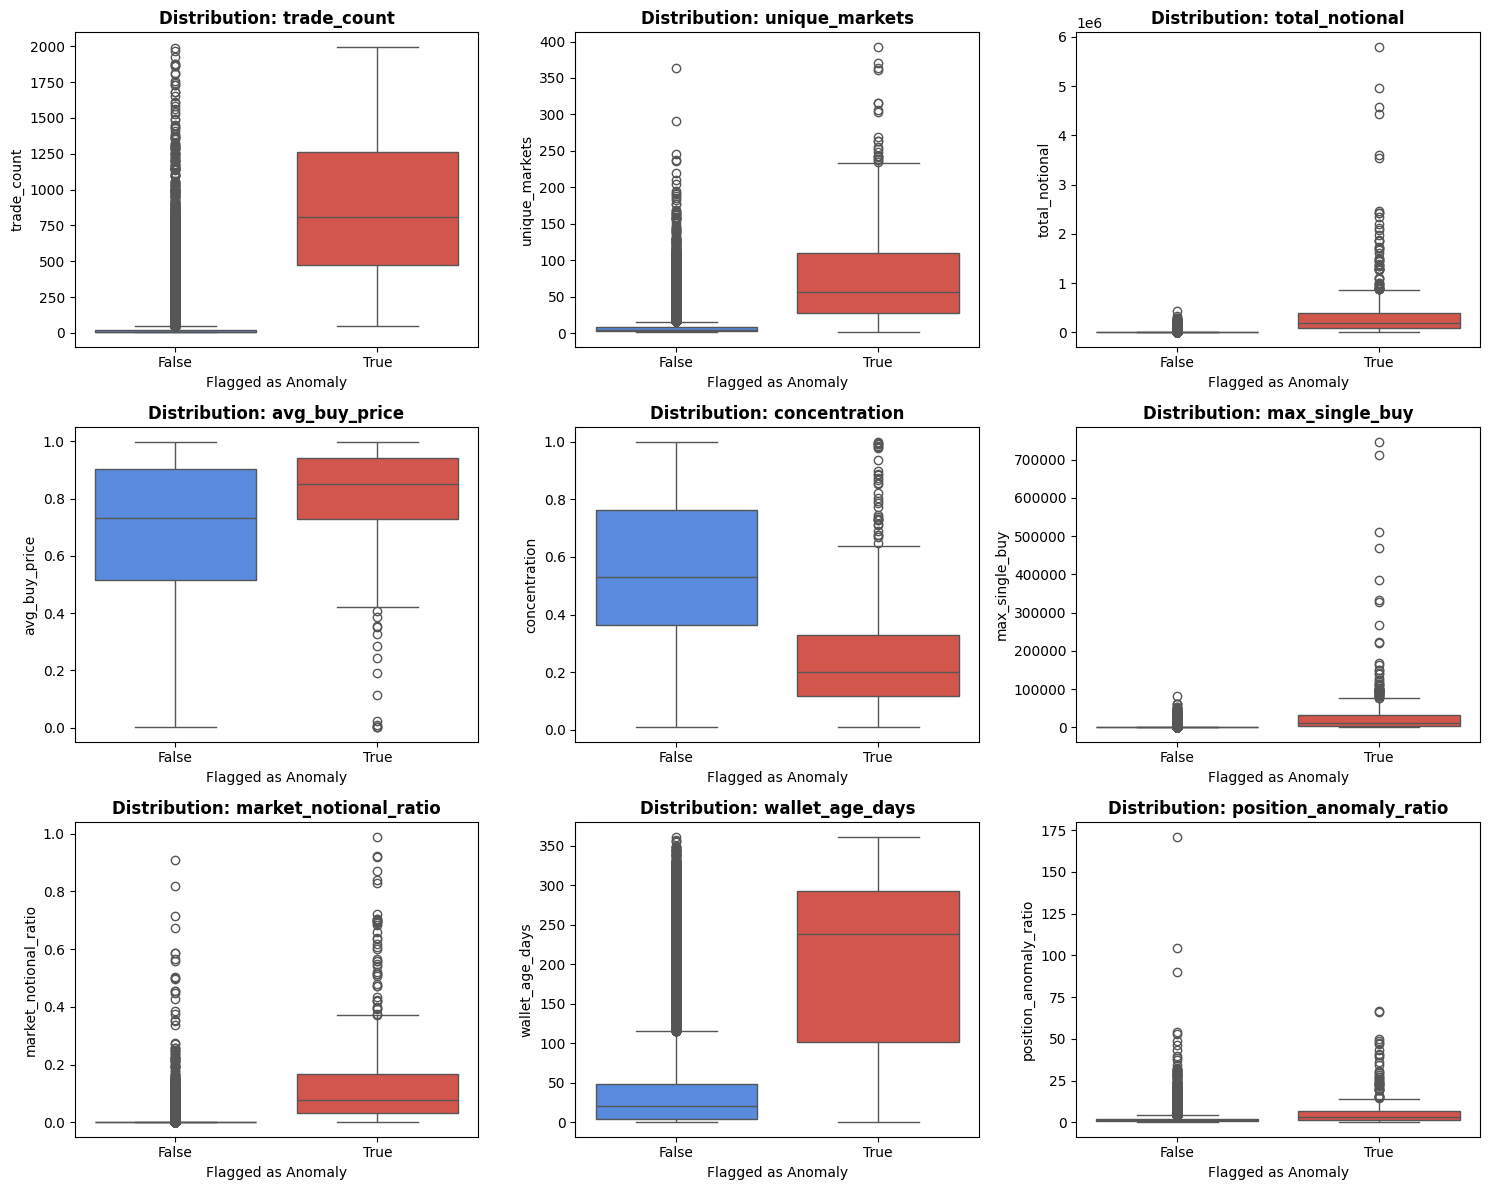

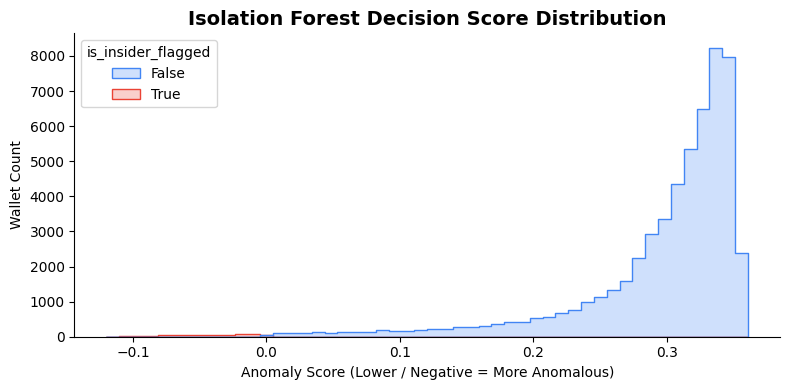


--- Top 10 Ranked Anomaly Wallets ---
           wallet  anomaly_score  trade_count  unique_markets  total_notional
6    w_cdb76c15a1      -0.119851         1580             137    4.911291e+05
22   w_47659a4732      -0.112764         1553             131    1.860667e+06
61   w_f7ca2ed140      -0.111586         1481             100    1.850843e+06
115  w_1a6b6adb7f      -0.110024         1308              69    1.506350e+06
2    w_4fad99896f      -0.108850         1972             264    2.478366e+05
34   w_d550bf600a      -0.108303         1913             127    1.443188e+06
113  w_deaa3be4fc      -0.108303         1145              71    2.430703e+06
345  w_e28f7c7158      -0.105578         1894              24    5.799982e+06
388  w_9db0c9cf6c      -0.104491         1313              43    3.529958e+06
16   w_8c69cfa6f4      -0.102320          334              52    1.471645e+05


In [3]:
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Isolate Flagged Wallets vs Normal Wallets
flagged_df = df[df["is_insider_flagged"]].copy()
normal_df = df[~df["is_insider_flagged"]].copy()

print(f"Total Flagged Anomaly Wallets: {len(flagged_df)}")
print(f"Confirmed Insiders in Flagged Set: {retrieved_count}")

# 2. Feature Summary Comparison (Mean & Median)
# Compares numerical feature averages to spot what sets top anomalies apart
print("\n--- Mean Feature Values Comparison ---")
summary_df = df.groupby("is_insider_flagged")[X.columns].mean().T
summary_df.columns = ["Normal Wallets", "Flagged Anomaly Wallets"]
summary_df["Ratio (Flagged / Normal)"] = summary_df["Flagged Anomaly Wallets"] / summary_df["Normal Wallets"]
print(summary_df)

# 3. Distribution Boxplots for Key Numerical Features
# Visualizes skewness and outliers in flagged wallets vs normal population
num_features = len(X.columns)
cols = 3
rows = (num_features + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(15, 4 * rows))
axes = axes.flatten()

for idx, col in enumerate(X.columns):
    sns.boxplot(
        data=df,
        x="is_insider_flagged",
        y=col,
        ax=axes[idx],
        palette=["#4285F4", "#EA4335"]
    )
    axes[idx].set_title(f"Distribution: {col}", fontsize=12, fontweight="bold")
    axes[idx].set_xlabel("Flagged as Anomaly")
    axes[idx].set_xticklabels(["False", "True"])

# Hide unused subplots
for idx in range(num_features, len(axes)):
    fig.delaxes(axes[idx])

plt.tight_layout()
plt.show()

# 4. Anomaly Decision Scores (Severity Ranking)
# Scores closer to -1 represent the most extreme anomalies
df["anomaly_score"] = iso_forest.decision_function(X)

plt.figure(figsize=(8, 4))
sns.histplot(
    data=df,
    x="anomaly_score",
    hue="is_insider_flagged",
    element="step",
    bins=50,
    palette=["#4285F4", "#EA4335"]
)
plt.title("Isolation Forest Decision Score Distribution", fontsize=14, fontweight="bold")
plt.xlabel("Anomaly Score (Lower / Negative = More Anomalous)")
plt.ylabel("Wallet Count")
sns.despine()
plt.tight_layout()
plt.show()

# 5. Top 10 Most Extreme Anomaly Wallets
if "wallet" in df.columns:
    top_anomalies = df.sort_values(by="anomaly_score").head(10)
    print("\n--- Top 10 Ranked Anomaly Wallets ---")
    print(top_anomalies[["wallet", "anomaly_score"] + list(X.columns[:3])])